# Разведочный анализ данных (EDA)
### Исследование качества датасета CoRE MOF

**Главная цель анализа** — оценить чистоту данных, найти скрытые аномалии и пропуски.



In [29]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore

import warnings
warnings.filterwarnings('ignore')

## 1. Загрузка файла в формате Parquet и первичный анализ структуры

На данном этапе выполняется чтение исходного датасета из оптимизированного формата Parquet. Выводятся данные из начала и конца DataFrame. Представлена размерность исходного датасета. Проверены типы данных. Загрузка датасета с гугл диска, приведение типов данных и приведение к формату Parquet осущесвляется в скрипте data_loader.py.




In [30]:
df = pd.read_parquet('../dataset.parquet')
df.head(5)


,filename,LCD,PLD,LFPD,cm3_g,ASA_m2_cm3,ASA_m2_g,NASA_m2_cm3,NASA_m2_g,AV_VF,...,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41
0,ABAVIJ_clean,4.457031,2.498047,4.406250,1.525391,0.0,0.00,312.0000,204.6250,0.379150,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ABAVOP_clean,3.537109,2.441406,3.529297,1.566406,0.0,0.00,122.8125,78.4375,0.378174,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ABAYIO_clean,11.398438,4.324219,11.273438,0.949219,1429.0,1505.00,409.5000,431.5000,0.663574,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ABAYOU_clean,11.273438,4.511719,11.273438,0.979492,1463.0,1494.00,419.0000,428.0000,0.663574,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ABEFUL_clean,4.941406,3.330078,4.937500,1.550781,418.5,269.75,0.0000,0.0000,0.411865,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
df.tail(5)

,filename,LCD,PLD,LFPD,cm3_g,ASA_m2_cm3,ASA_m2_g,NASA_m2_cm3,NASA_m2_g,AV_VF,...,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41
14137,ZUQBUK_clean,6.601562,3.876953,6.601562,0.987305,2005.0,2031.0,0.0,0.000,0.580078,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14138,ZUSNOS_clean,13.062500,6.722656,12.148438,0.801758,2346.0,2926.0,0.0,0.000,0.709961,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14139,ZUTBAR03_clean,5.664062,2.833984,5.664062,2.679688,0.0,0.0,879.0,328.000,0.489746,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14140,ZUTBAR05_clean,5.628906,2.787109,5.628906,2.687500,0.0,0.0,833.0,310.250,0.481445,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14141,ZUWWAP_clean,5.074219,2.677734,5.074219,2.085938,0.0,0.0,528.5,253.375,0.464111,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
print(f"Размерность датасета: {df.shape}")


Размерность датасета: (14142, 42)


In [33]:
df.dtypes

filename                          str
LCD                           float16
PLD                           float16
LFPD                          float16
cm3_g                         float16
ASA_m2_cm3                    float16
ASA_m2_g                      float16
NASA_m2_cm3                   float16
NASA_m2_g                     float16
AV_VF                         float16
AV_cm3_g                      float16
NAV_cm3_g                     float16
All_Metals                   category
Has_OMS                          bool
Open_Metal_Sites                  str
Extension                    category
FSR_overlap                      bool
from_CSD                         bool
public                           bool
DISORDER                          str
CSD_overlap_inCoRE               bool
CSD_of_WoS_inCoRE                 str
CSD_overlap_inCCDC               bool
date_CSD                       string
DOI_public                        str
Note                              str
Matched_CSD_

## 2. Анализ полноты данных 

Для оценки целостности данных рассчитывается количество пропусков по столбцам, а также их относительная доля в процентах по каждому доступному признаку. 



In [34]:
missing_values = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_table = pd.DataFrame({'Missing Values': missing_values,'Percentage': missing_percent})
missing_table


,Missing Values,Percentage
filename,0,0.000000
LCD,0,0.000000
PLD,0,0.000000
LFPD,0,0.000000
cm3_g,0,0.000000
ASA_m2_cm3,0,0.000000
ASA_m2_g,0,0.000000
NASA_m2_cm3,0,0.000000
NASA_m2_g,0,0.000000
AV_VF,0,0.000000


### Автоматические предупреждения 

Запускается скрипт, который показывает критические зоны (где пропусков больше 70% и 95%).


In [35]:
for col in missing_table.index:
    percent = missing_table.loc[col, 'Percentage']
    if percent > 95:
        print(f"КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка '{col}' имеет {percent:.2f}% пропущенных значений. Рекомендуется удалить эту колонку из анализа.")
    elif percent > 70:
        print(f"ПРЕДУПРЕЖДЕНИЕ: Колонка '{col}' имеет {percent:.2f}% пропущенных значений. Рекомендуется рассмотреть возможность удаления этой колонки из анализа.")

ПРЕДУПРЕЖДЕНИЕ: Колонка 'DISORDER' имеет 83.39% пропущенных значений. Рекомендуется рассмотреть возможность удаления этой колонки из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'CSD_of_WoS_inCoRE' имеет 97.31% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'date_CSD' имеет 96.87% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'DOI_public' имеет 96.87% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'Note' имеет 96.87% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'Matched_CSD_of_CoRE' имеет 96.87% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'Possible_List_CSD_of_CoRE' имеет 99.24% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'Unna

### Очистка данных 

**Что мы удаляем и почему:**
* **Служебные метаданные баз данных (CSD / CCDC / WoS):** Колонки `CSD_of_WoS_inCoRE`, `date_CSD`, `DOI_public`, `Note`, `Matched_CSD_of_CoRE`, `Possible_List_CSD_of_CoRE` и пустые поля `Unnamed`содержали критический объем пропусков (до **99.9%**). Это просто индексы перекрестных ссылок внешних каталогов. Физического смысла в них нет. 

* **Технические флаги (`from_CSD`, `public`, `FSR_overlap`):** Заполнены на 100%, но содержат бинарные метки публикации. Данные поля не несут физико-химического или геометрического смысла пористой структуры (таких как пористость, диаметр пор или площадь поверхности) и избыточны для дальнейших аналитических задач. 

**Что мы оставляем:**
* **Колонка `DISORDER` (разупорядоченность кристаллической решетки):** содержит 83.39% пропусков. Несмотря на высокую разреженность, этот параметр является критически важным физическим фактором при анализе дефектов и стабильности металл-органических каркасов (MOF). Признак осознанно сохранен в датасете для проведения дальнейшего специфического анализа.


In [36]:
columns_to_remove = [
    'CSD_of_WoS_inCoRE',
    'date_CSD',
    'DOI_public',
    'Note',
    'Matched_CSD_of_CoRE',
    'Possible_List_CSD_of_CoRE',
    'FSR_overlap',
    'from_CSD',
    'public',
    'CSD_overlap_inCoRE',
    'CSD_overlap_inCCDC'
]

unnamed_cols = [col for col in df.columns if 'Unnamed:' in col]
columns_to_remove.extend(unnamed_cols)
df = df.drop(columns=columns_to_remove, errors='ignore')

print(f"Размерность датасета после удаления колонок: {df.shape}")
df.head(5)


Размерность датасета после удаления колонок: (14142, 17)


,filename,LCD,PLD,LFPD,cm3_g,ASA_m2_cm3,ASA_m2_g,NASA_m2_cm3,NASA_m2_g,AV_VF,AV_cm3_g,NAV_cm3_g,All_Metals,Has_OMS,Open_Metal_Sites,Extension,DISORDER
0,ABAVIJ_clean,4.457031,2.498047,4.406250,1.525391,0.0,0.00,312.0000,204.6250,0.379150,0.248657,0.0,Co,True,,clean,NaN
1,ABAVOP_clean,3.537109,2.441406,3.529297,1.566406,0.0,0.00,122.8125,78.4375,0.378174,0.241455,0.0,Co,True,,clean,NaN
2,ABAYIO_clean,11.398438,4.324219,11.273438,0.949219,1429.0,1505.00,409.5000,431.5000,0.663574,0.699219,0.0,Mn,True,,clean,NaN
3,ABAYOU_clean,11.273438,4.511719,11.273438,0.979492,1463.0,1494.00,419.0000,428.0000,0.663574,0.677734,0.0,Co,True,,clean,NaN
4,ABEFUL_clean,4.941406,3.330078,4.937500,1.550781,418.5,269.75,0.0000,0.0000,0.411865,0.265381,0.0,Tb,True,,clean,NaN


## 3. Поиск выбросов и аномалий

Применяется сравнительный анализ двух подходов:
1. **Метод Z-score:** выявление экстремальных отклонений от математического ожидания с фиксированным жестким порогом $|Z| > 3$ .
2. **Метод Межквартильного размаха (IQR):** локализация математических выбросов относительно медианы распределения по формуле $[Q_1 - 1.5 \times IQR ; Q_3 + 1.5 \times IQR]$.

По каждому целевому физико-химическому признаку выводится описательная статистика с помощью метода `.describe()`.



Признак: LCD
Количество выбросов по методу z-score: 271
Количество выбросов по методу IQR: 860
count    860.000000
mean      18.750000
std        5.511719
min       13.796875
25%       15.091797
50%       16.984375
75%       20.347656
max       71.625000
Name: LCD, dtype: float64


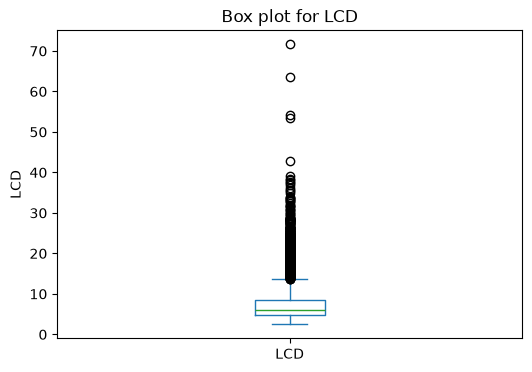

Признак: PLD
Количество выбросов по методу z-score: 212
Количество выбросов по методу IQR: 781
count    781.000000
mean      13.171875
std        5.292969
min        9.585938
25%       10.343750
50%       11.117188
75%       13.734375
max       71.500000
Name: PLD, dtype: float64


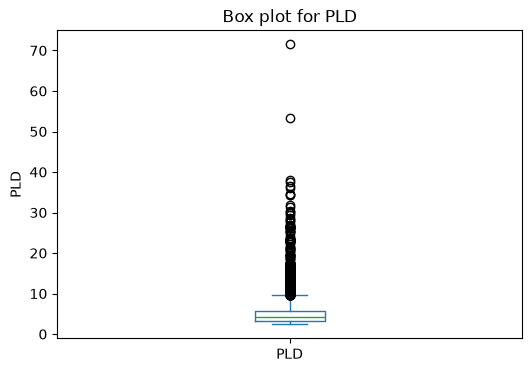

Признак: LFPD
Количество выбросов по методу z-score: 262
Количество выбросов по методу IQR: 853
count    853.000000
mean      18.546875
std        5.531250
min       13.625000
25%       15.039062
50%       16.843750
75%       20.265625
max       71.625000
Name: LFPD, dtype: float64


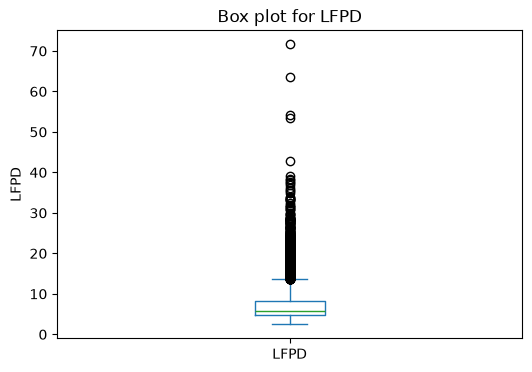

Признак: cm3_g
Количество выбросов по методу z-score: 173
Количество выбросов по методу IQR: 362
count    362.000000
mean       3.031250
std        0.599121
min        0.056915
25%        2.655762
50%        2.875977
75%        3.281250
max        7.457031
Name: cm3_g, dtype: float64


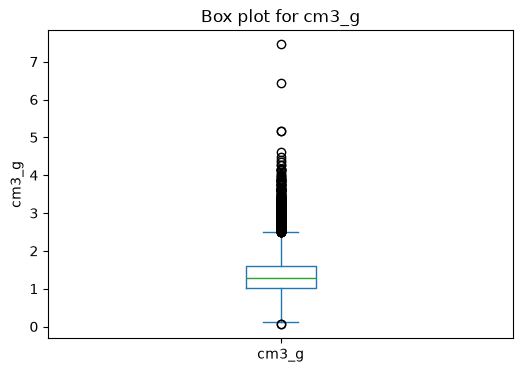

Признак: ASA_m2_g
Количество выбросов по методу z-score: 0
Количество выбросов по методу IQR: 306
count     306.0
mean        inf
std         inf
min      4328.0
25%      4630.0
50%      4890.0
75%      5187.0
max      8320.0
Name: ASA_m2_g, dtype: float64


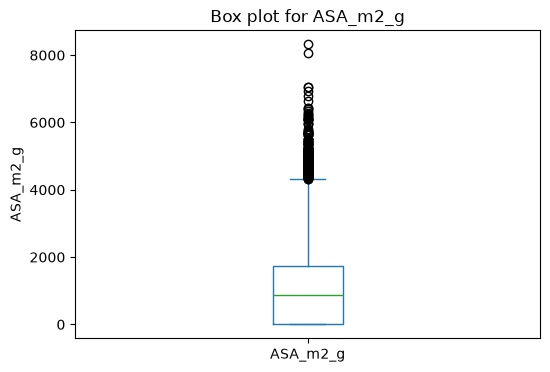

In [37]:
import warnings
warnings.filterwarnings('ignore')

target_features = ['LCD','PLD','LFPD', 'cm3_g','ASA_m2_g']
for col in target_features:
    if col in df.columns:
        print(f"Признак: {col}")
        # 1. Метод z-score
        df['z_score'] = zscore(df[col])
        df_outliers_z = df[abs(df['z_score']) > 3]
        print(f"Количество выбросов по методу z-score: {len(df_outliers_z)}")

        # 2. Метод IQR
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        df['is_outlier_iqr'] = (df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))
        df_outliers_iqr = df[df['is_outlier_iqr']] 
        print(f"Количество выбросов по методу IQR: {len(df_outliers_iqr)}")

        print(df_outliers_iqr[col].describe())

        plt.figure(figsize=(6, 4))
        df[col].plot.box()
        plt.title(f"Box plot for {col}")
        plt.ylabel(col)
        plt.show()
        
        

### Разбор аномалий на основе графиков

**1. Физические выбросы  (`LCD`, `PLD`, `LFPD`, `cm3_g`):**
* Графики показывают длинные хвосты с точками. 
* Это не технические ошибки, а реальные физические свойства — редкие ультрапористые MOF-структуры с огромными порами.
* Удалять их нельзя, иначе потеряем ценные уникальные материалы.

**2. Аномалия в `ASA_m2_g` (Площадь поверхности):**
* Описательная статистика выбросов выдала **`mean = inf`** и **`std = inf`**.
* Наличие бесконечностей (`inf`) — это серьезная аномалия качества данных. Скорее всего возникло при делении на ноль. 



## 4. Итоговый отчет по качеству данных 

* **Полнота признаков:** Основные структурные параметры пор заполнены на 100%.
* **Оптимизация:** Успешно удалено 25 мусорных колонок метаданных внешних каталогов. Размерность сокращена с 42 до 17 столбцов.
* **Качество данных:** Обнаружена критическая семантическая ошибка (бесконечности в `ASA_m2_g`), которая требует обязательной предобработки.
